# Experimento 2: comparación de modelos entrenados y de referencia (2017)

**Objetivo:** evaluar si un modelo entrenado sobre el conjunto de datos (LightGBM o una red neuronal de tamaño reducido) supera a los modelos de referencia del experimento 1, y si existe un modelo con precisión aceptable que pueda ejecutarse en el ESP32-S3.

Diferencias respecto al notebook 01:
- Partición temporal por años: entrenamiento 2014–2015, validación 2016, prueba 2017.
- Evaluación sobre las 52 semanas de 2017 (el experimento 1 evaluó 4 semanas de diciembre).
- Se incorporan dos modelos entrenados: LightGBM y un perceptrón multicapa (MLP).

La justificación de las decisiones de diseño se documenta en `README.md`, sección 5.

**Ejecución:** se recomienda una primera corrida con `PRUEBA_RAPIDA = True` (20 series y entrenamiento reducido, aprox. 4 minutos) para verificar el entorno, y luego la corrida completa con `PRUEBA_RAPIDA = False` (estimado: 10–15 minutos con GPU; aprox. 1 hora solo con CPU).

Chronos y la red neuronal se ejecutan en la GPU si PyTorch tiene soporte CUDA (`README.md`, sección 8). LightGBM se ejecuta en CPU.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"  # Keras sobre PyTorch (instalado con Chronos); TensorFlow solo se requiere en el notebook 03

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras
import lightgbm as lgb
from chronos import BaseChronosPipeline

PRUEBA_RAPIDA = False  # True: 20 series y entrenamiento reducido, para verificar la ejecución

H = 7          # horizonte de pronóstico (días)
VENTANA = 28   # longitud del historial reciente (días)
ANIO = 364     # desfase anual de 52 semanas: conserva el día de la semana
VERSION = "v0.1"  # los modelos de cada versión se guardan en su propia carpeta
MODELOS_DIR = f"../models/{VERSION}"
os.makedirs(MODELOS_DIR, exist_ok=True)
keras.utils.set_random_seed(42)  # reproducibilidad del entrenamiento de la red

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"  # GPU NVIDIA si PyTorch tiene soporte CUDA; Keras la detecta automáticamente
print("Dispositivo de cómputo:", DISPOSITIVO, torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "")

c:\Users\davfy\Documents\proeycts\tinyml-inventory-forecast\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo de cómputo: cuda NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 1. Carga de datos

Las ventas se organizan en una matriz `Y` de dimensión (series × días), donde cada fila corresponde a una combinación tienda-producto. Este formato facilita la extracción de ventanas temporales.

In [2]:
raw = pd.read_csv("../data/train.csv", parse_dates=["date"])
raw["unique_id"] = "tienda" + raw.store.astype(str) + "_prod" + raw.item.astype(str)
tabla = raw.pivot(index="unique_id", columns="date", values="sales")
if PRUEBA_RAPIDA:
    tabla = tabla.iloc[:20]

fechas, ids = tabla.columns, tabla.index
assert tabla.notna().all().all() and len(fechas) == (fechas[-1] - fechas[0]).days + 1, "el conjunto tiene días faltantes"
Y = tabla.to_numpy(dtype="float32")
print(f"Y: {Y.shape[0]} series x {Y.shape[1]} días ({fechas[0].date()} a {fechas[-1].date()})")

Y: 500 series x 1826 días (2013-01-01 a 2017-12-31)


## 2. Partición temporal

Se define como **origen** *t* el último día con información disponible: con los datos hasta *t* se pronostican los días *t*+1 a *t*+7. Este esquema reproduce la operación en producción, donde el origen es el día actual.

| Conjunto | Orígenes | Uso |
|---|---|---|
| Entrenamiento | diarios, 2014–2015 | ajuste de parámetros |
| Validación | diarios, 2016 | parada temprana (*early stopping*) |
| Prueba | semanales, 2017 (52) | evaluación final, una sola vez |

El entrenamiento inicia en enero de 2014 porque cada origen requiere 28 días de historial reciente y un año adicional para la variable de estacionalidad anual. Los cortes semanales de prueba coinciden con los del notebook 01.

In [3]:
def idx(fecha):
    return fechas.get_loc(pd.Timestamp(fecha))

primer_origen = ANIO + VENTANA - 1
orig_train = np.arange(primer_origen, idx("2015-12-31") - H + 1)
orig_val = np.arange(idx("2015-12-31"), idx("2016-12-31") - H + 1)
orig_test = np.arange(idx("2017-01-01"), idx("2017-12-31") - H + 1, H)

# ningún objetivo de entrenamiento o validación pertenece al año siguiente
assert orig_train[-1] + H <= idx("2015-12-31") and orig_val[-1] + H <= idx("2016-12-31")
print(f"orígenes: entrenamiento {len(orig_train)} | validación {len(orig_val)} | prueba {len(orig_test)} semanas")

orígenes: entrenamiento 697 | validación 360 | prueba 52 semanas


## 3. Variables de entrada

Para cada serie y cada origen *t* se construye un vector de 42 variables:
- 28 rezagos (*t*−27 … *t*), normalizados por la media de los últimos 28 días (escala).
- 7 valores de la misma semana del año anterior, normalizados por la media de los 28 días previos a esa semana.
- 7 variables indicadoras (*one-hot*) del día de la semana de *t*+1.

La normalización permite entrenar un único modelo global sobre series de distinto volumen. Se excluyen el identificador del producto y la fecha calendario para que el modelo sea aplicable a otros inventarios.

**Variable objetivo:** ventas de *t*+1 a *t*+7 divididas por la escala. Las predicciones se multiplican por la escala para expresarlas en unidades.

In [4]:
def armar_pistas(Y, t):
    """Variables de entrada de todas las series en el origen t. Retorna X (series x 42) y la escala de cada serie."""
    reciente = Y[:, t - VENTANA + 1 : t + 1]
    # shortcut: series con media < 1 unidad/día no se normalizan (escala = 1); revisar con datos reales de demanda intermitente
    escala = np.maximum(reciente.mean(axis=1, keepdims=True), 1)
    hace_un_anio = Y[:, t - ANIO + 1 : t - ANIO + 1 + H]
    base_anio = np.maximum(Y[:, t - ANIO - VENTANA + 1 : t - ANIO + 1].mean(axis=1, keepdims=True), 1)
    dia_semana = np.zeros((len(Y), 7), dtype="float32")
    dia_semana[:, (fechas[t].dayofweek + 1) % 7] = 1
    return np.hstack([reciente / escala, hace_un_anio / base_anio, dia_semana]), escala


def armar_tabla(origenes):
    """Apila las variables de varios orígenes. Orden de filas: origen 1 (todas las series), origen 2, ..."""
    Xs, ys, escalas = [], [], []
    for t in origenes:
        X, escala = armar_pistas(Y, t)
        Xs.append(X)
        ys.append(Y[:, t + 1 : t + 1 + H] / escala)
        escalas.append(escala)
    return np.vstack(Xs), np.vstack(ys), np.vstack(escalas)


Xtr, ytr, _ = armar_tabla(orig_train)
Xva, yva, _ = armar_tabla(orig_val)
Xte, _, escala_te = armar_tabla(orig_test)
print("entrenamiento:", Xtr.shape, "| validación:", Xva.shape, "| prueba:", Xte.shape)

n_sem, n_prod = len(orig_test), len(Y)
real = np.stack([Y[:, t + 1 : t + 1 + H] for t in orig_test])  # valores observados de prueba: (semanas, series, días)
pred = {}

entrenamiento: (348500, 42) | validación: (180000, 42) | prueba: (26000, 42)


## 4. Modelos de referencia

- **Naive estacional (semanal):** el pronóstico de cada día es el valor observado siete días antes. Establece el desempeño mínimo aceptable.
- **Chronos-Bolt small:** modelo preentrenado, mejor resultado del experimento 1. Se utiliza sin reentrenamiento (*zero-shot*), con todo el historial disponible hasta cada origen.

Tiempo de inferencia medido para 500 series: aprox. 0.8 s por semana en GPU (RTX 3050) y 42 s por semana en CPU.

In [5]:
pred["Naive_semanal"] = np.stack([Y[:, t - H + 1 : t + 1] for t in orig_test])

chronos = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map=DISPOSITIVO, torch_dtype=torch.float32)
semanas = []
for t in orig_test:
    q, _ = chronos.predict_quantiles(torch.tensor(Y[:, : t + 1]), prediction_length=H, quantile_levels=[0.5])
    semanas.append(q[..., 0].numpy())
pred["Chronos"] = np.stack(semanas)

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 1208.46it/s]


## 5. LightGBM

Modelo de *gradient boosting* sobre árboles de decisión. Se entrena un modelo independiente por cada día del horizonte (estrategia directa, 7 modelos).

- Función objetivo `l1` (error absoluto), cuyo estimador óptimo es la mediana; el resultado es comparable con el P50 de Chronos.
- Parada temprana: se agregan árboles mientras el error de validación (2016) disminuye; el entrenamiento se detiene tras 50 iteraciones sin mejora.
- Reentrenamiento final sobre 2014–2016 con el número de árboles seleccionado.

In [6]:
params = dict(objective="l1", learning_rate=0.05, num_leaves=31, min_data_in_leaf=200,
              feature_fraction=0.8, verbose=-1, seed=42)
rondas = 50 if PRUEBA_RAPIDA else 2000

lgb_modelos = []
for k in range(H):
    # .copy(): LightGBM advierte cuando recibe una columna no contigua en memoria
    m = lgb.train(params, lgb.Dataset(Xtr, ytr[:, k].copy()), rondas,
                  valid_sets=[lgb.Dataset(Xva, yva[:, k].copy())], callbacks=[lgb.early_stopping(50, verbose=False)])
    final = lgb.train(params, lgb.Dataset(np.vstack([Xtr, Xva]), np.concatenate([ytr[:, k], yva[:, k]])), m.best_iteration)
    final.save_model(f"{MODELOS_DIR}/lightgbm_dia{k + 1}.txt")
    lgb_modelos.append(final)
    print(f"día {k + 1}: {m.best_iteration} árboles")

pred["LightGBM"] = (np.column_stack([m.predict(Xte) for m in lgb_modelos]) * escala_te).reshape(n_sem, n_prod, H)

día 1: 310 árboles
día 2: 345 árboles
día 3: 411 árboles
día 4: 420 árboles
día 5: 408 árboles
día 6: 521 árboles
día 7: 508 árboles


## 6. Red neuronal (MLP)

Arquitectura: 42 entradas → capa densa de 64 neuronas (ReLU) → capa densa de 32 neuronas (ReLU) → 7 salidas, una por día del horizonte. Total: 5,063 parámetros (aprox. 20 KB en float32 y 5 KB en int8), compatible con la memoria del ESP32-S3.

- Función de pérdida: error absoluto medio (MAE), por consistencia con LightGBM.
- Optimizador Adam (tasa de aprendizaje 1e-3) con lotes de 512 ejemplos.
- Parada temprana con paciencia de 5 épocas sobre la validación; luego, reentrenamiento desde cero sobre 2014–2016 con el número de épocas seleccionado.
- La curva de aprendizaje permite detectar sobreajuste: aumento del error de validación mientras disminuye el de entrenamiento.

5,063 parámetros | mejor época: 11


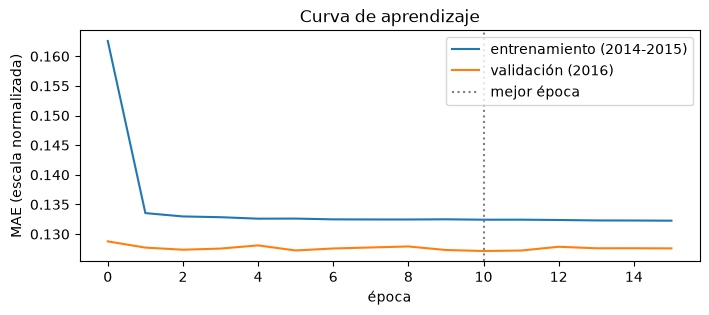

In [7]:
def crear_red():
    red = keras.Sequential([
        keras.Input(shape=(Xtr.shape[1],)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(H),
    ])
    red.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")
    return red

epocas = 2 if PRUEBA_RAPIDA else 100
red = crear_red()
hist = red.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epocas, batch_size=512, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
mejor = int(np.argmin(hist.history["val_loss"])) + 1

red = crear_red()
red.fit(np.vstack([Xtr, Xva]), np.vstack([ytr, yva]), epochs=mejor, batch_size=512, verbose=0)
red.save(f"{MODELOS_DIR}/red.keras")
print(f"{red.count_params():,} parámetros | mejor época: {mejor}")

pred["Red_neuronal"] = (red.predict(Xte, verbose=0) * escala_te).reshape(n_sem, n_prod, H)

plt.figure(figsize=(8, 3))
plt.plot(hist.history["loss"], label="entrenamiento (2014-2015)")
plt.plot(hist.history["val_loss"], label="validación (2016)")
plt.axvline(mejor - 1, color="gray", ls=":", label="mejor época")
plt.xlabel("época"); plt.ylabel("MAE (escala normalizada)"); plt.title("Curva de aprendizaje"); plt.legend()

## 7. Resultados

Se emplean las métricas del experimento 1 (`README.md`, sección 3.3), calculadas sobre las 52 semanas de 2017. La columna de tamaño indica la memoria que ocupa cada modelo, criterio determinante para su ejecución en el ESP32-S3.

El control verifica la consistencia con el notebook 01: el MAE del modelo naive en las cuatro semanas de diciembre debe ser 8.74.

In [8]:
assert all(p.shape == real.shape for p in pred.values())

def metricas(p):
    err = p - real
    return {"MAE (unidades/día)": np.abs(err).mean(),
            "WAPE": np.abs(err).sum() / real.sum(),
            "Sesgo": err.sum() / real.sum(),
            "WAPE semanal": np.abs(err.sum(axis=2)).sum() / real.sum()}

tam_kb = {"Naive_semanal": 0,
          "Chronos": 183_000,  # tamaño de los pesos descargados
          "LightGBM": sum(os.path.getsize(f"{MODELOS_DIR}/lightgbm_dia{k + 1}.txt") for k in range(H)) / 1024,  # archivos de texto del modelo
          "Red_neuronal": red.count_params() * 4 / 1024}  # float32: 4 bytes por parámetro; en int8 se reduce a la cuarta parte

resultados = pd.DataFrame({m: metricas(p) for m, p in pred.items()}).T
resultados["Tamaño (KB)"] = pd.Series(tam_kb)
print(f"Control: MAE naive en diciembre = {np.abs(pred['Naive_semanal'][-4:] - real[-4:]).mean():.2f} (notebook 01: 8.74)")
resultados.sort_values("WAPE semanal").style.format(
    {"MAE (unidades/día)": "{:.2f}", "WAPE": "{:.1%}", "Sesgo": "{:+.1%}", "WAPE semanal": "{:.1%}", "Tamaño (KB)": "{:,.0f}"})

Control: MAE naive en diciembre = 8.74 (notebook 01: 8.74)


,MAE (unidades/día),WAPE,Sesgo,WAPE semanal,Tamaño (KB)
LightGBM,6.41,10.9%,-0.3%,5.2%,"8,861"
Red_neuronal,6.45,11.0%,-0.7%,5.3%,20
Naive_semanal,8.84,15.0%,-0.1%,6.5%,0
Chronos,7.01,11.9%,-1.3%,6.5%,"183,000"


### Error por mes

WAPE semanal promedio por mes. Permite identificar si algún modelo se degrada en los cambios de temporada, como la caída de diciembre observada en el experimento 1.

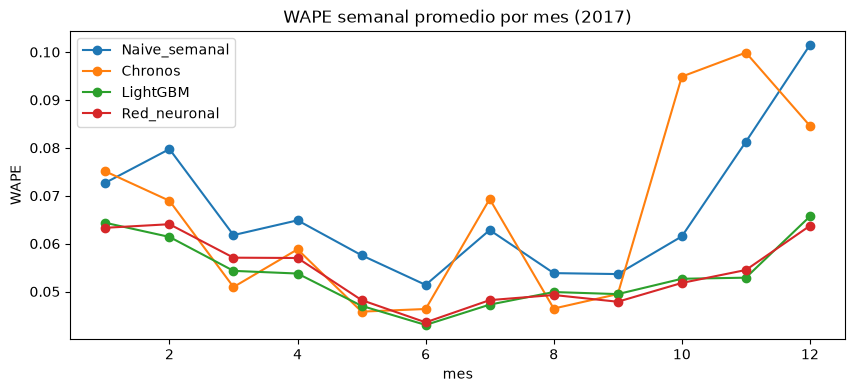

In [9]:
def wape_por_semana(p):
    return np.abs(p.sum(axis=2) - real.sum(axis=2)).sum(axis=1) / real.sum(axis=(1, 2))

meses = fechas[orig_test + 1].month
por_mes = pd.DataFrame({m: wape_por_semana(p) for m, p in pred.items()}, index=meses).groupby(level=0).mean()
por_mes.plot(marker="o", figsize=(10, 4), title="WAPE semanal promedio por mes (2017)", xlabel="mes", ylabel="WAPE");

### Ejemplo: una serie durante 2017

Total semanal observado frente al pronóstico de cada modelo.

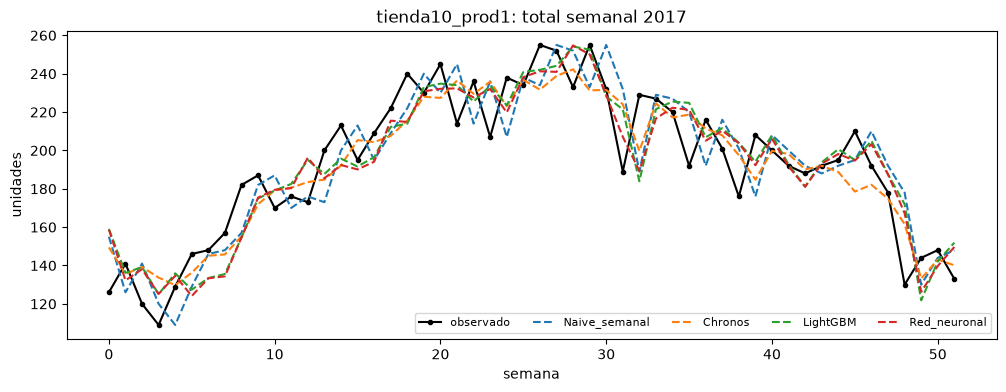

In [10]:
i = 0
plt.figure(figsize=(12, 4))
plt.plot(real[:, i].sum(axis=1), "k-o", ms=3, label="observado")
for m, p in pred.items():
    plt.plot(p[:, i].sum(axis=1), "--", label=m)
plt.title(f"{ids[i]}: total semanal 2017"); plt.xlabel("semana"); plt.ylabel("unidades"); plt.legend(ncol=5, fontsize=8);

## 8. Siguiente paso

Si la red neuronal supera al modelo naive, el notebook 03 la cuantiza a int8 (TensorFlow Lite), repite la evaluación sobre las mismas 52 semanas para medir la pérdida de precisión y genera el archivo para el firmware del ESP32-S3.